# Comparing solvers on three likelihood criteria

This notebook compares GALAHAD TRU and ARC with SciPy L-BFGS-B on Gaussian,
Bernoulli and Poisson criteria. Every method receives the same sample, zero start,
average-loss normalization and analytic gradient. GALAHAD additionally receives
an exact Hessian. Three clean repetitions follow one warm-up per method; reported
wall times are medians over those three repetitions with one BLAS thread.

Objective construction and derivative checking occur outside the timer. Native
initialization and cleanup are included. Instrumented convergence runs are separate
from the timed fits. These small examples describe the current kernel and do not
establish a general speed ranking.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1004)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from time import perf_counter
from scipy.special import expit
from scipy.optimize import minimize
from galahad_econometrics import Criterion, tru, arc, check_derivatives

n, p = 5000, 6
D = np.column_stack([np.ones(n), rng.normal(size=(n, p - 1))])
beta = np.array([.2, .4, -.3, .2, .1, -.2])
eta = D @ beta
responses = {"Gaussian": eta + .5*rng.normal(size=n),
             "Bernoulli": rng.binomial(1, expit(eta)),
             "Poisson": rng.poisson(np.exp(eta))}

def make_criterion(family, design, y):
    n = len(y)
    if family == "Gaussian":
        H = design.T @ design / n
        def fun(b):
            r = design @ b - y
            return float(r @ r / (2*n))
        def grad(b):
            return design.T @ (design @ b - y) / n
        def hess(b):
            return H
    else:
        def fun(b):
            z = design @ b
            loss = np.logaddexp(0, z) - y*z if family == "Bernoulli" else np.exp(z) - y*z
            return float(np.mean(loss))
        def grad(b):
            z = design @ b
            mu = expit(z) if family == "Bernoulli" else np.exp(z)
            return design.T @ (mu - y) / n
        def hess(b):
            z = design @ b
            w = expit(z)*expit(-z) if family == "Bernoulli" else np.exp(z)
            return design.T @ (w[:, None] * design) / n
    return Criterion(fun, grad, hess)

criteria = {family: make_criterion(family, D, y) for family, y in responses.items()}
for criterion in criteria.values():
    assert max(check_derivatives(criterion, np.full(p, .1)).values()) < 1e-6

## Time the same estimation task

The common accuracy check requires gradient norm at most `1e-6` and relative
objective gap at most `1e-8`. Native stopping flags are retained separately.
L-BFGS-B is used without bounds; its curvature approximation differs from the
exact-Hessian methods. The Gaussian criterion is squared loss up to a positive
constant, so its minimizer is the OLS estimator.

In [3]:
def run_method(name, criterion):
    start = np.zeros(p)
    if name == "SciPy L-BFGS-B":
        return minimize(criterion.fun, start, jac=criterion.grad, method="L-BFGS-B",
                        options={"gtol": 1e-8, "ftol": 1e-15, "maxiter": 1000})
    module = {"TRU": tru, "ARC": arc}[name]
    return module.solve(criterion, start)

rows, references, diagnostics = [], {}, {}
for family, criterion in criteria.items():
    if family == "Gaussian":
        reference = np.linalg.lstsq(D, responses[family], rcond=None)[0]
    else:
        reference = minimize(criterion.fun, np.zeros(p), jac=criterion.grad, hess=criterion.hess,
                             method="trust-exact", options={"gtol": 1e-10, "maxiter": 1000}).x
    assert np.linalg.norm(criterion.grad(reference)) < 1e-6
    references[family] = reference
    for method in ["TRU", "ARC", "SciPy L-BFGS-B"]:
        run_method(method, criterion)  # Untimed warm-up.
        elapsed, outputs = [], []
        for repeat in range(3):
            started = perf_counter()
            output = run_method(method, criterion)
            elapsed.append(perf_counter() - started)
            outputs.append(output)
        checked = [np.linalg.norm(criterion.grad(r.x)) <= 1e-6
                   and (criterion.fun(r.x) - criterion.fun(reference)) / max(1, abs(criterion.fun(reference))) <= 1e-8
                   for r in outputs]
        assert all(checked), (family, method)
        rows.append({"family": family, "method": method, "median ms": 1000*np.median(elapsed),
                     "common check": all(checked), "native flags": all(bool(r.success) for r in outputs),
                     "gradient norm": np.linalg.norm(criterion.grad(outputs[-1].x))})
    for name, module in [("TRU", tru), ("ARC", arc)]:
        diagnostics[family, name] = module.solve(criterion, np.zeros(p), trace=True)

summary = pd.DataFrame(rows)
summary

,family,method,median ms,common check,native flags,gradient norm
0,Gaussian,TRU,0.48446,True,True,3.3987e-16
1,Gaussian,ARC,0.85842,True,True,3.5364e-09
2,Gaussian,SciPy L-BFGS-B,0.38046,True,True,1.248e-09
3,Bernoulli,TRU,1.478,True,True,3.484e-15
4,Bernoulli,ARC,2.0445,True,True,7.554e-10
5,Bernoulli,SciPy L-BFGS-B,1.0535,True,True,6.6348e-09
6,Poisson,TRU,1.325,True,True,8.8074e-09
7,Poisson,ARC,1.5551,True,True,4.1341e-12
8,Poisson,SciPy L-BFGS-B,1.211,True,True,7.4455e-10


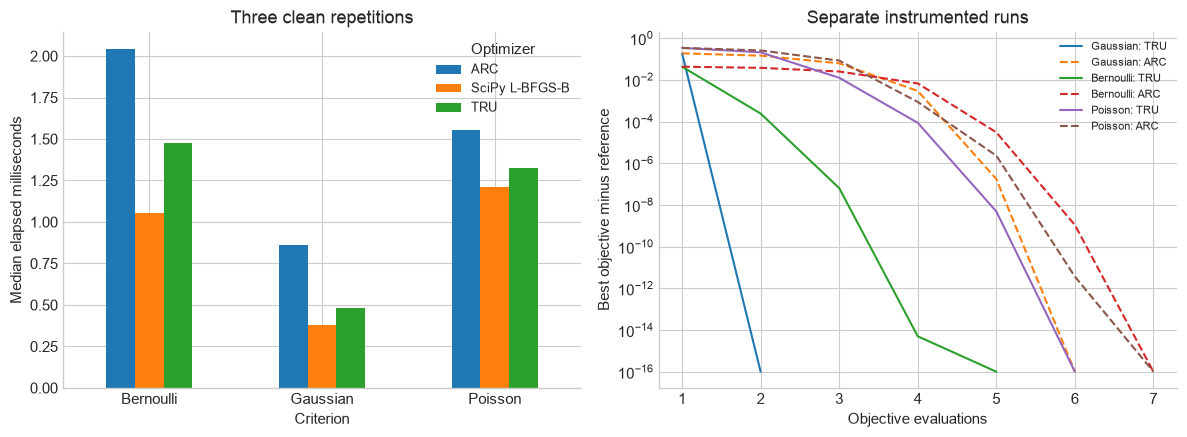

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
summary.pivot(index="family", columns="method", values="median ms").plot.bar(ax=axes[0], rot=0)
axes[0].set(xlabel="Criterion", ylabel="Median elapsed milliseconds", title="Three clean repetitions")
axes[0].legend(title="Optimizer", fontsize=9)
for (family, method), result in diagnostics.items():
    fref = criteria[family].fun(references[family])
    values = np.array([point.objective for point in result.history])
    gap = np.maximum(np.minimum.accumulate(values) - fref, 1e-16)
    axes[1].semilogy(np.arange(1, len(gap)+1), gap,
                     linestyle="-" if method == "TRU" else "--", label=f"{family}: {method}")
axes[1].set(xlabel="Objective evaluations", ylabel="Best objective minus reference",
            title="Separate instrumented runs")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

The timing table and plot retain the individual solver names and averaging units.
Convergence curves are evaluation envelopes, not accepted iterates. Direct linear
algebra is still an appropriate default for OLS. Solver comparisons on nonlinear
objectives depend on data scale, curvature access, stopping rules and the
parameter dimension.